In [2]:
# Bibliotecas utilizadas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize

In [ ]:
# Rede Neural
class Redeneural:
    def __init__(self, input_size, hidden_size, output_size, Lambda, num_iters, alpha, classes=None):

        self.input_size = input_size
        self.output_size = output_size
        self.Lambda = Lambda
        self.num_iters = num_iters
        self.alpha = alpha

        # Número arbitrário de classes
        if classes is None:
            self.classes = None
        else:
            self.classes = np.asarray(classes)
            if len(self.classes) != output_size:
                raise ValueError("O número de classes deve ser igual a output_size.")
        
        # Número arbitrário de camadas e neurônios escondidos
        if isinstance(hidden_size, int):
            camadas_escondidas = [hidden_size]
        else:
            camadas_escondidas = list(hidden_size)

        self.layer_sizes = [input_size] + camadas_escondidas + [output_size]
        self.num_camadas = len(self.layer_sizes) - 1

        # Inicialização aleatória dos pesos
        self.Thetas = []

        for k in range(self.num_camadas):

            l_in = self.layer_sizes[k]
            l_out = self.layer_sizes[k + 1]

            epi = np.sqrt(6) / np.sqrt(l_in + l_out)
            Theta = np.random.rand(l_out, l_in + 1) * (2 * epi) - epi

            self.Thetas.append(Theta)

    # Transforma a lista de matrizes em um único vetor
    def pesos_para_vetor(self):

        vetor = np.array([])
        
        for Theta in self.Thetas:
            vetor = np.concatenate((vetor, Theta.flatten()))
        return vetor

    # Faz o caminho inverso: vetor -> lista de matrizes
    def vetor_para_pesos(self, vetor):
        
        self.Thetas = []
        inicio = 0

        for k in range(self.num_camadas):

            linhas = self.layer_sizes[k + 1]
            colunas = self.layer_sizes[k] + 1

            n = linhas * colunas
            Theta = vetor[inicio:inicio + n].reshape(linhas, colunas)
            
            self.Thetas.append(Theta)
            inicio += n

    # Ativação
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    # Derivada
    def sigmoid_gradient(self, z):
        return self.sigmoid(z) * (1 - self.sigmoid(z))

    # Propagação
    def forward(self, X):

        self.m = X.shape[0]
        entrada = np.vstack((np.ones((1, self.m)), X.T))

        self.a = [entrada]
        self.z = []

        for k in range(self.num_camadas):
            z = self.Thetas[k] @ self.a[k]
            ativacao = self.sigmoid(z)

            if k < self.num_camadas - 1:
                ativacao = np.vstack((np.ones((1, self.m)), ativacao))

            self.z.append(z)
            self.a.append(ativacao)

        return self.a[-1].T

    # Custo
    def cost_function(self, y, regularizar=True):
        
        y = np.asarray(y).ravel()

        if self.classes is None:
            self.classes = np.unique(y)
            if len(self.classes) != self.output_size:
                raise ValueError(
                    "O número de classes encontradas não é igual a output_size."
                )

        self.y10 = (y.reshape(1, -1) == self.classes.reshape(-1, 1)).astype(float)

        h = np.clip(self.a[-1], 1e-12, 1 - 1e-12)
        J = -np.sum(self.y10 * np.log(h) + (1 - self.y10) * np.log(1 - h)) / self.m

        if regularizar:
            
            soma_pesos = 0

            for Theta in self.Thetas:
                soma_pesos += np.sum(Theta[:, 1:] ** 2)
            J = J + self.Lambda / (2 * self.m) * soma_pesos

        return J

    # Backpropagation
    def backward(self):

        ultima_camada = self.num_camadas - 1
        grads = [None] * self.num_camadas

        delta = self.a[-1] - self.y10
        grads[ultima_camada] = delta @ self.a[ultima_camada].T / self.m

        for k in range(ultima_camada - 1, -1, -1):
            delta = (self.Thetas[k + 1][:, 1:].T @ delta) * self.sigmoid_gradient(self.z[k])
            grads[k] = delta @ self.a[k].T / self.m

        for k in range(self.num_camadas):
            Theta_sem_bias = self.Thetas[k].copy()
            Theta_sem_bias[:, 0] = 0
            grads[k] = grads[k] + (self.Lambda / self.m) * Theta_sem_bias

        self.grads = grads

        return grads

    # Função objetivo no formato exigido por scipy.optimize.minimize
    def cost_and_grad(self, vetor, X, y):

        self.vetor_para_pesos(vetor)
        self.forward(X)

        J = self.cost_function(y)
        grads = self.backward()

        vetor_gradiente = np.array([])
        for g in grads:
            vetor_gradiente = np.concatenate((vetor_gradiente, g.flatten()))

        return J, vetor_gradiente

    # Checagem do gradiente
    def gradient_check(self, X, y, epsilon=1e-4):

        theta = self.pesos_para_vetor()
        _, grad_anal = self.cost_and_grad(theta, X, y)
        grad_num = np.zeros_like(theta)

        for i in range(theta.size):
            theta_mais = theta.copy()
            theta_mais[i] += epsilon
            theta_menos = theta.copy()
            theta_menos[i] -= epsilon

            J_mais, _ = self.cost_and_grad(theta_mais, X, y)
            J_menos, _ = self.cost_and_grad(theta_menos, X, y)
            grad_num[i] = (J_mais - J_menos) / (2 * epsilon)

        self.vetor_para_pesos(theta)
        diff = np.linalg.norm(grad_num - grad_anal) / np.linalg.norm(grad_num + grad_anal)

        return grad_num, grad_anal, diff

    # Treinamento por gradiente descendente
    def GradientDescent(self, X, y):
        J_history = []

        for i in range(self.num_iters):
            self.forward(X)
            J_history.append(self.cost_function(y))
            grads = self.backward()

            novos_Thetas = []
            for Theta, grad in zip(self.Thetas, grads):
                novos_Thetas.append(Theta - self.alpha * grad)
            self.Thetas = novos_Thetas

        self.J_history = J_history
        return self.pesos_para_vetor(), J_history

    # Gradiente conjugado via scipy.optimize.minimize
    def trainCG(self, X, y, maxiter=400):

        res = minimize(self.cost_and_grad, self.pesos_para_vetor(), args=(X, y), jac=True, method="CG", options={"maxiter": maxiter})
        self.vetor_para_pesos(res.x)
        
        return res

    # Predição
    def predict(self, X):

        indices = np.argmax(self.forward(X), axis=1)
    
        if self.classes is None:
            raise ValueError("As classes ainda não foram definidas.")
    
        return self.classes[indices]

    # Devolve acurácia em %
    def _avaliar(self, X, y):

        pred = self.predict(X)
        acc = np.mean(pred == y) * 100
        erro = self.cost_function(y, regularizar=False)
        
        return acc, erro

    # Treina com todos os dados de uma vez, sem separar em treino, teste e validação
    def trainAll(self, X, y, metodo, maxiter, verbose):

        if metodo == "GD":
            self.GradientDescent(X, y)
        elif metodo == "CG":
            self.trainCG(X, y, maxiter=maxiter)
        else:
            raise ValueError("metodo deve ser 'GD' ou 'CG'.")

        predictions = self.predict(X)

        if verbose:
            accuracy = np.sum(predictions == y) / X.shape[0] * 100
            print(f"Porcentagem de imagens classificadas corretamente: {accuracy:.2f}%\n")

        return predictions

    # Treina no conjunto de treino e avalia acurácia e erro nos três conjuntos
    def trainSep(self, X_train, y_train, X_val, y_val, X_test, y_test, metodo, maxiter, verbose):

        if metodo == "GD":
            self.GradientDescent(X_train, y_train)
        elif metodo == "CG":
            self.trainCG(X_train, y_train, maxiter=maxiter)
        else:
            raise ValueError("metodo deve ser 'GD' ou 'CG'.")

        resultados = {
            "treino": self._avaliar(X_train, y_train),
            "validação": self._avaliar(X_val, y_val),
            "teste": self._avaliar(X_test, y_test),
            }
        
        if verbose:
            for nome, (acc, erro) in resultados.items():
                print(f"Conjunto de {nome}: acurácia = {acc:.2f}% | erro = {erro:.4f}")

        return resultados

In [146]:
# Leitura do conjunto de dados

X = pd.read_csv("imageMNIST.csv", decimal=",", header=None, low_memory=False).values.astype(float)
y = pd.read_csv("labelMNIST.csv", decimal=",", header=None, low_memory=False).values.flatten().astype(int)

classes = np.unique(y)
num_classes = len(classes)

# Função auxiliar para a divisão da base de dados
def split_data(X, y, test_size=0.2, val_size=0.2):

    if len(X) != len(y):
        raise ValueError("O tamanho de X e y deve ser o mesmo.")
    tam = X.shape[0]

    indices = np.arange(tam)
    np.random.shuffle(indices)
    X = X[indices]
    y = y[indices]

    fim_treino = int((1 - (test_size + val_size)) * tam)
    fim_val = int((1 - test_size) * tam)

    X_train, y_train = X[:fim_treino], y[:fim_treino]
    X_val, y_val = X[fim_treino:fim_val], y[fim_treino:fim_val]
    X_test, y_test = X[fim_val:], y[fim_val:]

    return X_train, X_val, X_test, y_train, y_val, y_test

Porcentagem de imagens classificadas corretamente: 94.56%

A rede classificou incorretamente 272 de 5000 imagens.

V: Número verdadeiro

P: Predição da Rede Neural



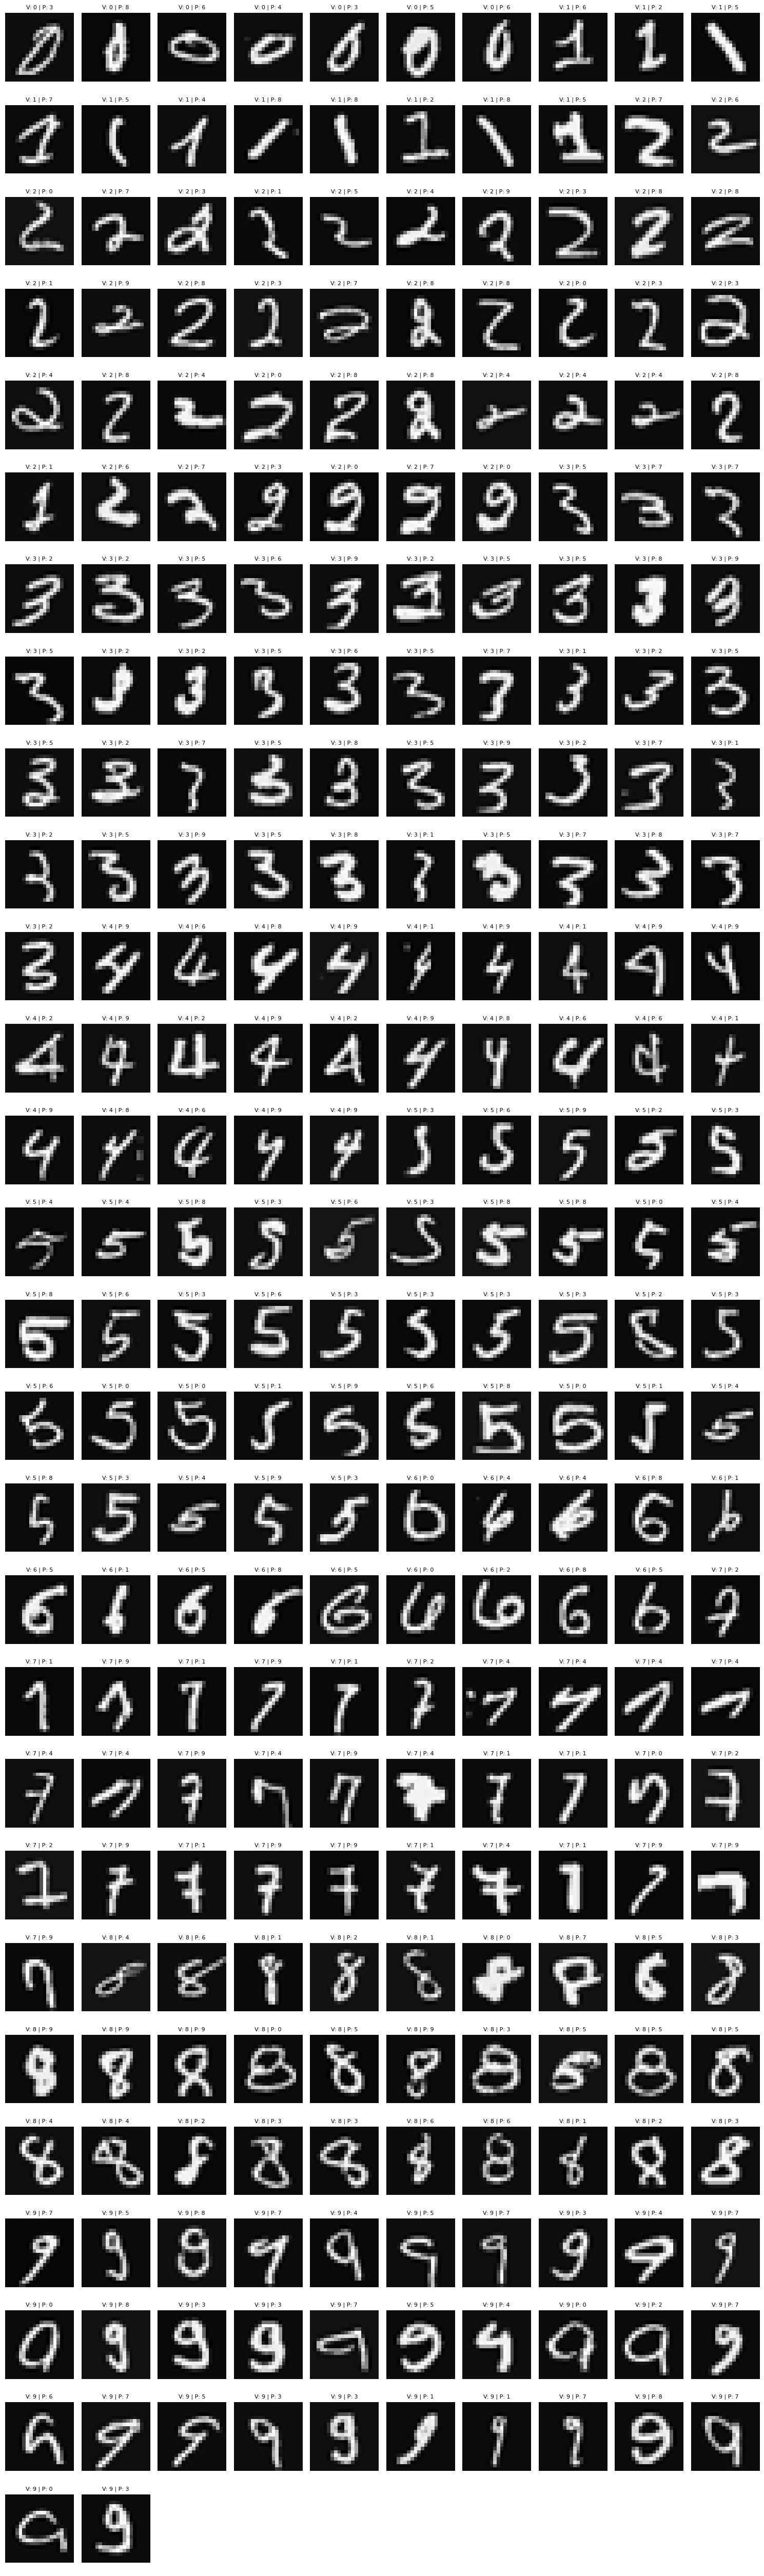

In [ ]:
# Parte I: Treinamento da Rede Neural Regularizada (25 neurônios escondidos)

# Reprodutibilidade dos resultados
np.random.seed(42)

# Inicialização da Rede Neural
rede_neural = Redeneural(input_size=X.shape[1], hidden_size=25, output_size=10, Lambda=1, num_iters=800, alpha=0.8, classes=classes)
previsoes = rede_neural.trainAll(X, y, metodo="GD", maxiter=800, verbose=True)

# Imagens classificadas incorretamente
indices_errados = np.where(previsoes != y)[0]
colunas = 10

print(f"A rede classificou incorretamente {len(indices_errados)} de {len(y)} imagens.\n")
print("V: Número verdadeiro\n")
print("P: Predição da Rede Neural\n")

if len(indices_errados) > 0:

    linhas = int(np.ceil(len(indices_errados) / colunas))
    
    fig, axs = plt.subplots(linhas, colunas, figsize=(1.5 * colunas, 1.8 * linhas), squeeze=False)

    for ax in axs.ravel():
        ax.axis("off")

    for ax, indice in zip(axs.ravel(), indices_errados):

        imagem = X[indice].reshape(20, 20, order="F")
        valor_verdadeiro = y[indice] % 10
        valor_previsto = previsoes[indice] % 10
        ax.imshow(imagem, cmap="gray")
        ax.set_title(f"V: {valor_verdadeiro} | P: {valor_previsto}", fontsize=8)

    plt.tight_layout()
    # plt.savefig('/home/miotto/Notebooks/MT571/erros_classificacao.png', dpi=300, bbox_inches='tight')
    plt.show()

else:
    print("Nenhuma imagem foi classificada incorretamente.")

In [148]:
# Parte I: Checagem do gradiente

# Reprodutibilidade dos resultados
np.random.seed(42)

# Dados fictícios
X_fake = np.random.rand(3, 3)
y_fake = np.array([0, 1, 2])

# Inicialização da Rede Neural
rede_teste = Redeneural(input_size=3, hidden_size=5, output_size=3, Lambda=1.0, num_iters=800, alpha=0.8, classes=[0,1,2])
g_num, g_analitico, diff = rede_teste.gradient_check(X_fake, y_fake, epsilon=1e-4)

print(f"Checagem do Gradiente para dados fictícios:\n")
print(pd.DataFrame({"Valor numérico": g_num, "Backpropagation": g_analitico}).head(10).to_string())
print()
print(f"Diferença relativa: {diff:.3e}\n")

Checagem do Gradiente para dados fictícios:

   Valor numérico  Backpropagation
0       -0.008362        -0.008362
1       -0.289170        -0.289170
2        0.264746         0.264746
3        0.185013         0.185013
4       -0.021910        -0.021910
5       -0.166384        -0.166384
6       -0.220266        -0.220266
7       -0.136867        -0.136867
8       -0.000614        -0.000614
9       -0.053942        -0.053942

Diferença relativa: 9.235e-11



In [149]:
# Parte I: Gradiente conjugado

# Reprodutibilidade dos resultados
np.random.seed(42)

lambdas = [0, 0.1, 1]
iteracoes = [50, 100, 400]

linhas = []
modelos = {}

for lam in lambdas:
    for it in iteracoes:
        
        rede_neural = Redeneural(input_size=X.shape[1], hidden_size=25, output_size=10, Lambda=lam, num_iters=it, alpha=0.8, classes=classes)
        predictions = rede_neural.trainAll(X, y, metodo="CG", maxiter=it, verbose=False)

        accuracy = np.mean(predictions == y) * 100
        modelos[(lam, it)] = rede_neural

        linhas.append({"lambda": lam, "iterações": it, "acurácia (%)": accuracy})

tabela = pd.DataFrame(linhas)
print(tabela.round(2).to_string(index=False))

# Escolha dos hiperparâmetros pela acurácia na VALIDAÇÃO
melhor_acuracia = tabela["acurácia (%)"].max()
melhores = tabela[tabela["acurácia (%)"] == melhor_acuracia]

print("\nMelhor(es) configuração(ões):")
print(melhores.round(2).to_string(index=False))
print(f"\nMelhor acurácia = {melhor_acuracia:.2f}%")

 lambda  iterações  acurácia (%)
    0.0         50         97.24
    0.0        100         99.90
    0.0        400        100.00
    0.1         50         97.08
    0.1        100         99.40
    0.1        400        100.00
    1.0         50         95.76
    1.0        100         98.40
    1.0        400         99.58

Melhor(es) configuração(ões):
 lambda  iterações  acurácia (%)
    0.0        400         100.0
    0.1        400         100.0

Melhor acurácia = 100.00%


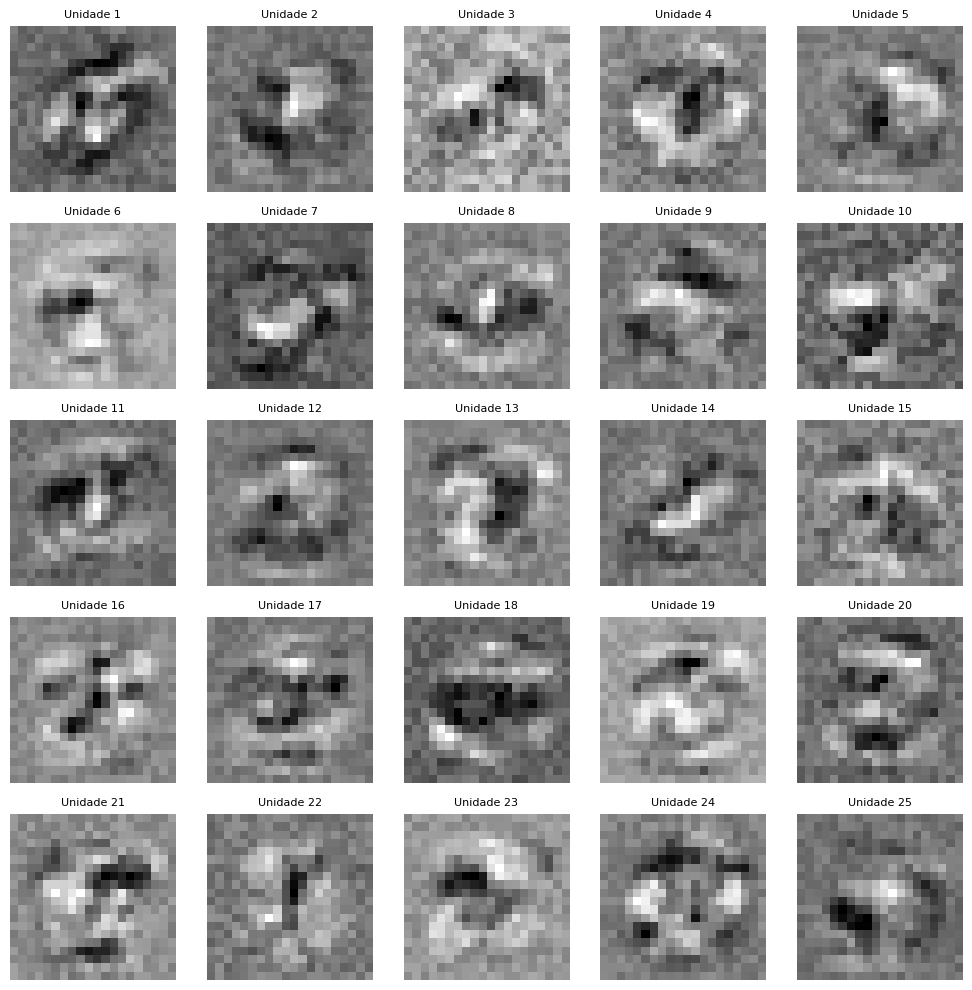

In [ ]:
# Parte I: Visualização do que cada unidade escondida "enxerga"

Theta = rede_neural.Thetas[0][:, 1:]
n_unidades = Theta.shape[0]
lado = int(np.sqrt(Theta.shape[1]))

n_cols = 5
n_rows = int(np.ceil(n_unidades / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2 * n_rows), squeeze=False)
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for i in range(n_unidades):

    imagem = Theta[i].reshape(lado, lado, order="F")

    minimo = imagem.min()
    maximo = imagem.max()

    if maximo > minimo:
        imagem = (imagem - minimo) / (maximo - minimo)

    axes[i].imshow(imagem, cmap="gray")
    axes[i].set_title(f"Unidade {i + 1}", fontsize=8)

plt.tight_layout()
# plt.savefig('/home/miotto/Notebooks/MT571/unidades_ocultas.png', dpi=300, bbox_inches='tight')
plt.show()

In [151]:
# Parte II: Divisão de exemplos

# Reprodutibilidade dos resultados
np.random.seed(42)

# Divisão da base de dados
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

rede_neural = Redeneural(input_size=X.shape[1], hidden_size=25, output_size=10, Lambda=1.0, num_iters=800, alpha=0.8, classes=classes)
_ = rede_neural.trainSep(X_train, y_train, X_val, y_val, X_test, y_test, metodo="GD", maxiter=800, verbose=True)

Conjunto de treino: acurácia = 94.97% | erro = 0.4170
Conjunto de validação: acurácia = 91.20% | erro = 0.5828
Conjunto de teste: acurácia = 92.00% | erro = 0.5779


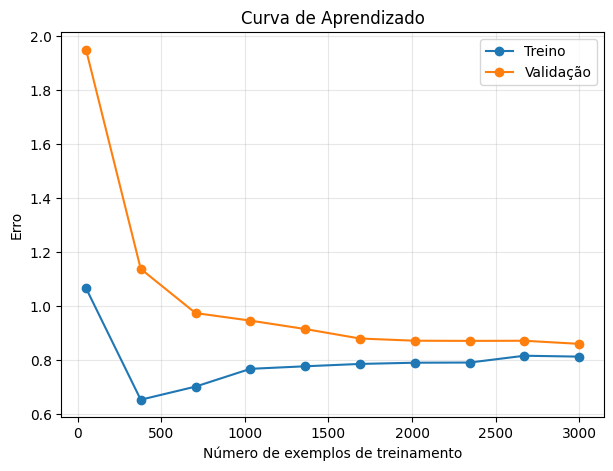

In [ ]:
# Parte II: Curva de Aprendizado

# Reprodutibilidade dos resultados
np.random.seed(42)

tamanhos_treino = np.linspace(max(50, num_classes * 5),len(X_train),10,dtype=int)
tamanhos_treino = np.unique(tamanhos_treino)

erros_treino = []
erros_validacao = []

for m in tamanhos_treino:

    rede_curva = Redeneural(input_size=X.shape[1], hidden_size=25, output_size=num_classes, Lambda=1.0, num_iters=200, alpha=0.8, classes=classes)
    rede_curva.trainAll(X_train[:m], y_train[:m], metodo="GD", maxiter=200, verbose=False)

    # Erro no próprio subconjunto usado para treinamento
    _, erro_train = rede_curva._avaliar(X_train[:m], y_train[:m])

    # Erro sempre no conjunto completo de validação
    _, erro_val = rede_curva._avaliar(X_val, y_val)

    erros_treino.append(erro_train)
    erros_validacao.append(erro_val)

plt.figure(figsize=(7, 5))

plt.plot(tamanhos_treino, erros_treino, marker="o", label="Treino")
plt.plot(tamanhos_treino, erros_validacao, marker="o", label="Validação")

plt.xlabel("Número de exemplos de treinamento")
plt.ylabel("Erro")
plt.title("Curva de Aprendizado")

plt.legend()
plt.grid(alpha=0.3)

# plt.savefig('/home/miotto/Notebooks/MT571/curva_aprendizado.png', dpi=300, bbox_inches='tight')

plt.show()

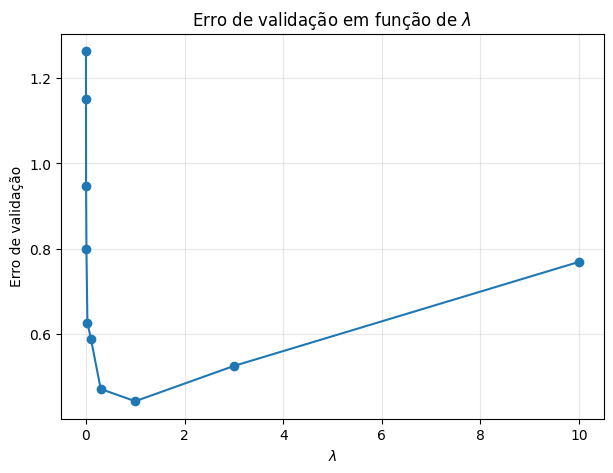


Melhor lambda: 1
Erro de validação: 0.44128

Resultado final no conjunto de teste:
Erro de teste: 0.46344
Acurácia de teste: 93.50%


In [157]:
# Parte II: Seleção automática de lambda

# Reprodutibilidade dos resultados
np.random.seed(42)

X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

lambdas = [0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]

erros_treino_lambda = []
erros_validacao_lambda = []
modelos_lambda = {}

for lam in lambdas:

    rede_lambda = Redeneural(input_size=X.shape[1], hidden_size=25, output_size=num_classes, Lambda=lam, num_iters=400, alpha=0.8, classes=classes)
    rede_lambda.trainAll(X_train, y_train, metodo="CG", maxiter=400, verbose=False)

    _, erro_train = rede_lambda._avaliar(X_train, y_train)
    _, erro_val = rede_lambda._avaliar(X_val, y_val)

    erros_treino_lambda.append(erro_train)
    erros_validacao_lambda.append(erro_val)

    modelos_lambda[lam] = rede_lambda

plt.figure(figsize=(7, 5))
plt.plot(lambdas, erros_validacao_lambda, marker="o")

plt.xlabel(r"$\lambda$")
plt.ylabel("Erro de validação")
plt.title(r"Erro de validação em função de $\lambda$")

plt.grid(alpha=0.3)

# plt.savefig('/home/miotto/Notebooks/MT571/erro_validacao_lambda.png', dpi=300, bbox_inches='tight')

plt.show()

indice_melhor = np.argmin(erros_validacao_lambda)
melhor_lambda = lambdas[indice_melhor]

print(f"\nMelhor lambda: {melhor_lambda}")
print(f"Erro de validação: {erros_validacao_lambda[indice_melhor]:.5f}")

melhor_rede = modelos_lambda[melhor_lambda]
acuracia_teste, erro_teste = melhor_rede._avaliar(X_test, y_test)

print(f"\nResultado final no conjunto de teste:")
print(f"Erro de teste: {erro_teste:.5f}")
print(f"Acurácia de teste: {acuracia_teste:.2f}%")

In [4]:
import pandas as pd

X = pd.read_csv(
    "imageMNIST.csv",
    decimal=",",
    low_memory=False
).values.astype(float)

y = pd.read_csv(
    "labelMNIST.csv",
    decimal=",",
    low_memory=False
).values

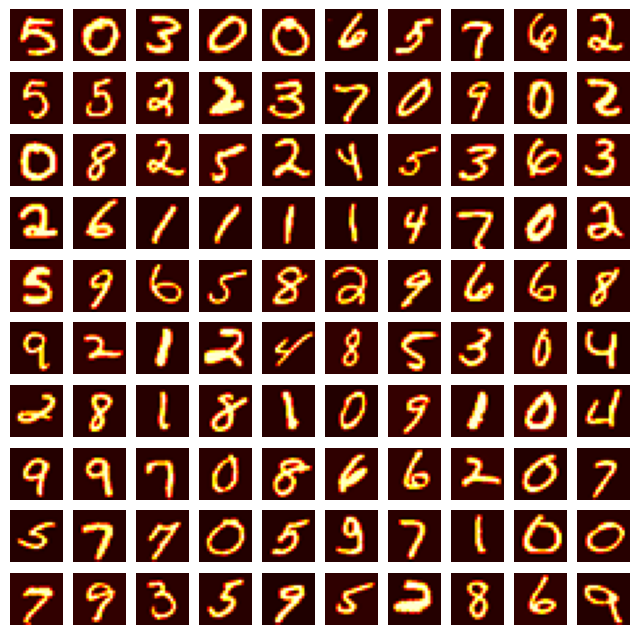

In [5]:
fig,axis = plt.subplots(10,10,figsize=(8,8))
for i in range(10):
    for j in range(10):
        axis[i,j].imshow(X[np.random.randint(0,5001),:].reshape(20,20,order="F"),cmap="hot")
        axis[i,j].axis("off")